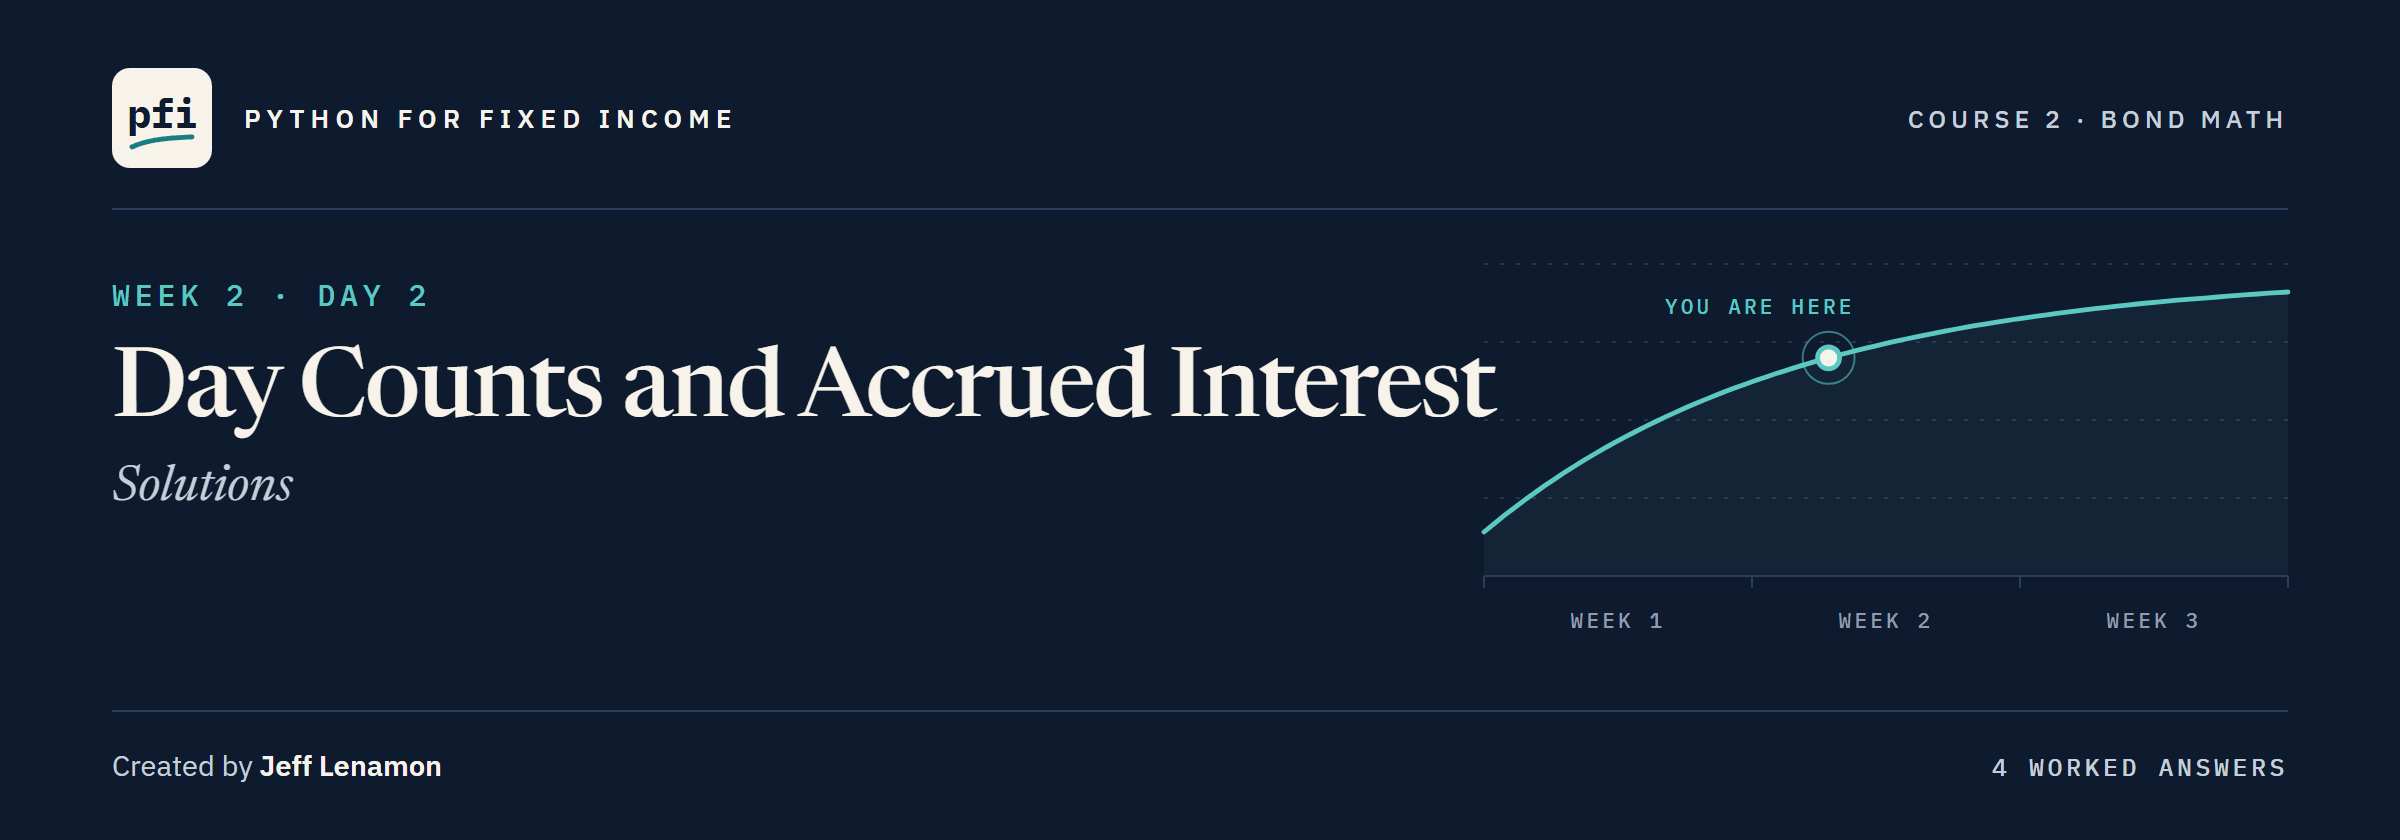

# Day Counts and Accrued Interest: Solutions

Week 2, Day 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day2/07_day_counts_and_accrued_interest_solutions.ipynb)

## Exercises

Run the next cells first: the work folder with the module as this notebook leaves it, the imports, `check`, and the trades.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 07 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(7, after=7)

Work folder pfi_course2_07_k4w7q2xr: 3 data files, the module as notebook 07 left it, 7 commits, tagged week1


In [2]:
import importlib
from datetime import date

import pandas as pd

import bondmath
print(bondmath.accrued_interest(date(2026, 11, 30), date(2031, 9, 30), 5.25))

0.875


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
exercise_bonds = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'maturity': [date(2030, 9, 30), date(2028, 9, 30), date(2032, 9, 30), date(2034, 9, 30)],
})
# one trade in each bond: the settlement date and the face, in dollars
exercise_trades = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'settlement': [date(2027, 2, 28), date(2027, 3, 1), date(2026, 12, 31), date(2027, 1, 15)],
    'par': [2_000_000, 5_000_000, 3_000_000, 1_500_000],
}).merge(exercise_bonds[['ticker', 'coupon_pct', 'maturity']], on='ticker')
exercise_trades

,ticker,settlement,par,coupon_pct,maturity
0,OSTV,2027-02-28,2000000,5.625,2030-09-30
1,TRNW,2027-03-01,5000000,4.375,2028-09-30
2,OSMC,2026-12-31,3000000,5.000,2032-09-30
3,CLDB,2027-01-15,1500000,8.250,2034-09-30


### Exercise 1

In [5]:
# A is item 0 of coupon_period_days; the accrued uses the module's 30/360 default
exercise_trades['a'] = [bondmath.coupon_period_days(s, m)[0] for s, m in zip(
    exercise_trades['settlement'], exercise_trades['maturity'])]
exercise_trades['accrued'] = [bondmath.accrued_interest(s, m, c) for s, m, c in zip(
    exercise_trades['settlement'], exercise_trades['maturity'], exercise_trades['coupon_pct'])]
print(exercise_trades[['ticker', 'settlement', 'a', 'accrued']])
ostrevale = exercise_trades[exercise_trades['ticker'] == 'OSTV'].iloc[0]
ex1_days, ex1_accrued = ostrevale['a'], ostrevale['accrued']

  ticker  settlement    a   accrued
0   OSTV  2027-02-28  148  2.312500
1   TRNW  2027-03-01  151  1.835069
2   OSMC  2026-12-31   90  1.250000
3   CLDB  2027-01-15  105  2.406250


Ostrevale settles on 28 February 2027, a February month end, and 30/360 counts 148 days from 30 September.

In [6]:
check('Exercise 1 Ostrevale days accrued', ex1_days, 148)
check('Exercise 1 Ostrevale accrued per 100', ex1_accrued, 2.3125)

Exercise 1 Ostrevale days accrued: correct
Exercise 1 Ostrevale accrued per 100: correct


### Exercise 2

In [7]:
exercise_trades['calendar'] = [(s - date(2026, 9, 30)).days for s in exercise_trades['settlement']]
exercise_trades['gap'] = exercise_trades['calendar'] - exercise_trades['a']
print(exercise_trades[['ticker', 'calendar', 'a', 'gap']])
widest = exercise_trades.loc[exercise_trades['gap'].idxmax()]
ex2_ticker, ex2_gap = widest['ticker'], widest['gap']

  ticker  calendar    a  gap
0   OSTV       151  148    3
1   TRNW       152  151    1
2   OSMC        92   90    2
3   CLDB       107  105    2


October, December, and January have 31 days, each counted as 30 on 30/360; February's 28 count the same on both, since rule 1 moves only a start.

In [8]:
check('Exercise 2 ticker with the largest gap', ex2_ticker, 'OSTV')
check('Exercise 2 largest gap in days', ex2_gap, 3)

Exercise 2 ticker with the largest gap: correct
Exercise 2 largest gap in days: correct


### Exercise 3

In [9]:
%%writefile -a bondmath.py


def accrued_dollars(par: float, accrued_per_100: float) -> float:
    """Accrued interest on a position, in dollars.

    Units: par in dollars of face; accrued_per_100 per 100 of face, as accrued_interest returns it.
    Convention: par x accrued_per_100 / 100. Excel: =par*accrued/100
    """
    return par * accrued_per_100 / 100

Appending to bondmath.py


In [10]:
%%writefile -a test_bondmath.py


def test_accrued_dollars_hand_case():
    # 1,000,000 of Quorvane on 30 November 2026 at 0.875 per 100
    assert bondmath.accrued_dollars(1_000_000, 0.875) == pytest.approx(8750.00)
    # nothing accrued, on a coupon date
    assert bondmath.accrued_dollars(1_000_000, 0.0) == 0

Appending to test_bondmath.py


In [11]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................                                                      [100%]
19 passed in 0.50s



In [12]:
# the file changed, so read it again before calling the new function
importlib.reload(bondmath)
ex3_total = sum([bondmath.accrued_dollars(p, a)
                 for p, a in zip(exercise_trades['par'], exercise_trades['accrued'])])
print(f'Accrued over the four trades: {ex3_total:,.2f} dollars')

Accrued over the four trades: 211,597.22 dollars


In [13]:
check('Exercise 3 accrued in dollars, four trades', ex3_total, 211597.22222222222)

Exercise 3 accrued in dollars, four trades: correct


### Exercise 4: AI check

The code counts calendar days over a 365-day year, so Quorvane came back as 0.877397 instead of 0.875.
The docstring asked for one coupon times A / E from `coupon_period_days`: the fix is two lines.

In [14]:
def assistant_accrued_interest(settlement, maturity, coupon_pct, frequency=2, basis='30/360'):
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    if basis not in ('30/360', 'ACT/ACT'):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the fix: A and E on the bond's own basis, and one coupon, not a year's
    days_accrued, days_in_period, _ = bondmath.coupon_period_days(settlement, maturity, frequency,
                                                                  basis)
    return coupon_pct / frequency * days_accrued / days_in_period

In [15]:
rows = pd.read_csv('bondmath_excel_reference.csv')
for case, s, m, c, f, b, excel in zip(rows['case_id'], rows['settlement'], rows['maturity'],
                                      rows['coupon_pct'], rows['frequency'], rows['basis'],
                                      rows['accrued']):
    basis = '30/360' if b == 0 else 'ACT/ACT'
    result = assistant_accrued_interest(date.fromisoformat(s), date.fromisoformat(m), c, f, basis)
    assert abs(result - excel) < 1e-9, f'{case}: accrued {result:.6f}, Excel {excel:.6f}'
print(f'All {len(rows)} rows match Excel')
ex4_quorvane = assistant_accrued_interest(date(2026, 11, 30), date(2031, 9, 30), 5.25)
ex4_osmere = assistant_accrued_interest(date(2026, 12, 31), date(2032, 9, 30), 5.0)

All 306 rows match Excel


The first row, `99080CAE8`, stopped the old code: a calendar count over 365 is not this bond's convention.

In [16]:
check('Exercise 4 Quorvane accrued', ex4_quorvane, 0.875)
check('Exercise 4 Osmere accrued', ex4_osmere, 1.25)

Exercise 4 Quorvane accrued: correct
Exercise 4 Osmere accrued: correct


[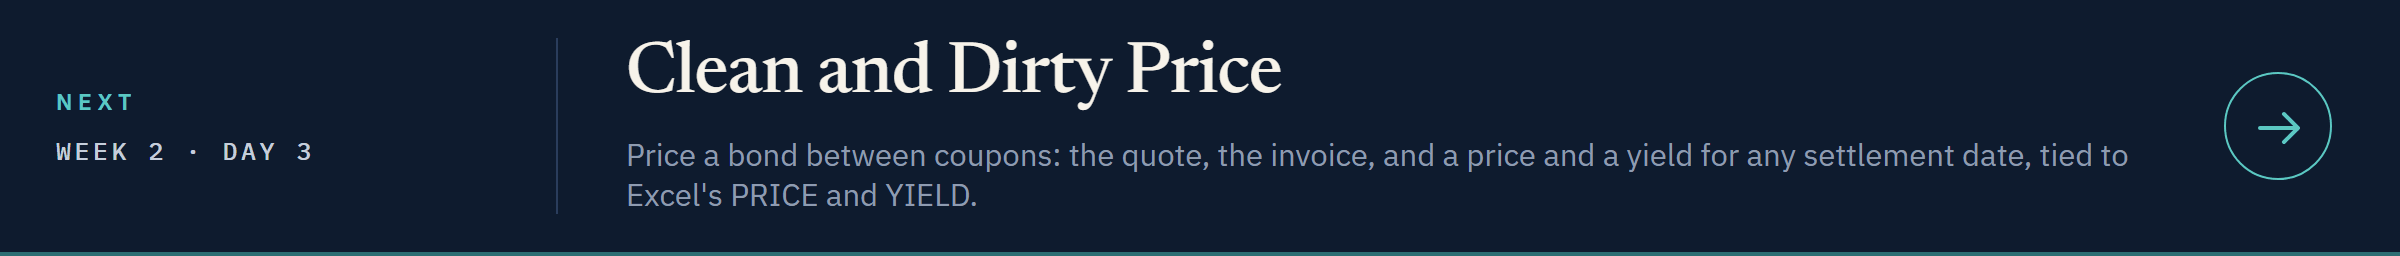](../day3/08_clean_and_dirty_price.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day3/08_clean_and_dirty_price.ipynb)